In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")

### Dataset Load

In [2]:
df = pd.read_csv("Advertising.csv")

if "Unnamed: 0" in df.columns:
    df.drop(columns=["Unnamed: 0"], inplace=True)

print(df.head())
print("\nShape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nDataset Information:")
df.info()

      TV  Radio  Newspaper  Sales
0  230.1   37.8       69.2   22.1
1   44.5   39.3       45.1   10.4
2   17.2   45.9       69.3    9.3
3  151.5   41.3       58.5   18.5
4  180.8   10.8       58.4   12.9

Shape: (200, 4)

Columns: ['TV', 'Radio', 'Newspaper', 'Sales']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   TV         200 non-null    float64
 1   Radio      200 non-null    float64
 2   Newspaper  200 non-null    float64
 3   Sales      200 non-null    float64
dtypes: float64(4)
memory usage: 6.4 KB


C:\Users\Admin\AppData\Local\Temp\ipykernel_4960\3749190122.py:4: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns=["Unnamed: 0"], inplace=True)


### Data Cleaning

In [3]:
print("Missing Values:\n", df.isnull().sum())
print("\nDuplicate Rows:", df.duplicated().sum())
print("\nStatistical Summary:\n", df.describe())

df = df.drop_duplicates().copy()
df = df.dropna(subset=["TV", "Radio", "Newspaper", "Sales"])

print("\nCleaned Dataset Shape:", df.shape)

Missing Values:
 TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64

Duplicate Rows: 0

Statistical Summary:
                TV       Radio   Newspaper       Sales
count  200.000000  200.000000  200.000000  200.000000
mean   147.042500   23.264000   30.554000   14.022500
std     85.854236   14.846809   21.778621    5.217457
min      0.700000    0.000000    0.300000    1.600000
25%     74.375000    9.975000   12.750000   10.375000
50%    149.750000   22.900000   25.750000   12.900000
75%    218.825000   36.525000   45.100000   17.400000
max    296.400000   49.600000  114.000000   27.000000

Cleaned Dataset Shape: (200, 4)


### Sales Distribution

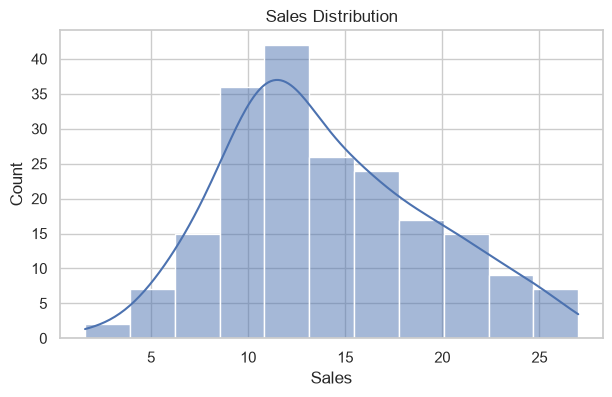

In [4]:
plt.figure(figsize=(7, 4))
sns.histplot(df["Sales"], kde=True)
plt.title("Sales Distribution")
plt.xlabel("Sales")
plt.show()

### Scatter Plots

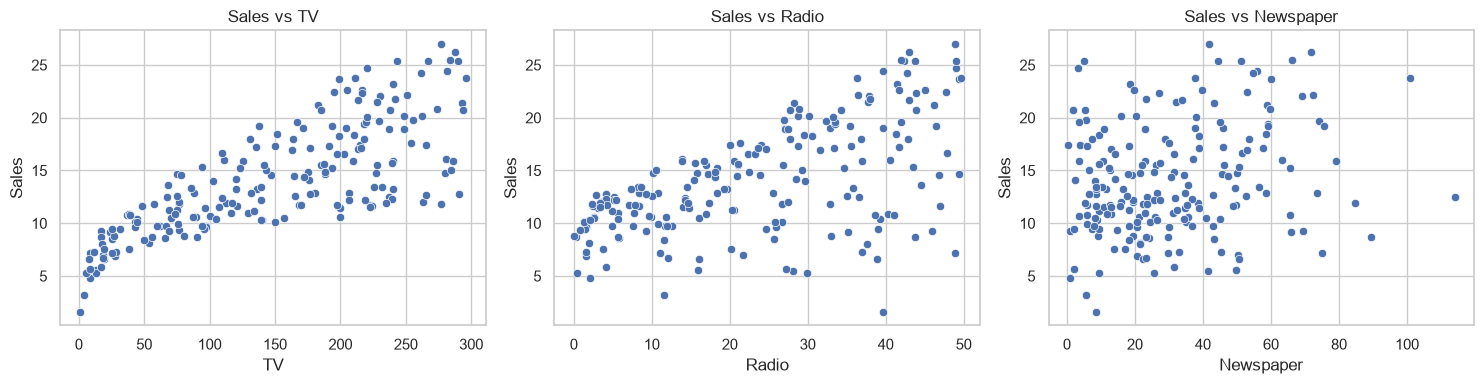

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.scatterplot(data=df, x="TV", y="Sales", ax=axes[0])
axes[0].set_title("Sales vs TV")

sns.scatterplot(data=df, x="Radio", y="Sales", ax=axes[1])
axes[1].set_title("Sales vs Radio")

sns.scatterplot(data=df, x="Newspaper", y="Sales", ax=axes[2])
axes[2].set_title("Sales vs Newspaper")

plt.tight_layout()
plt.show()

### Correlation Heatmap

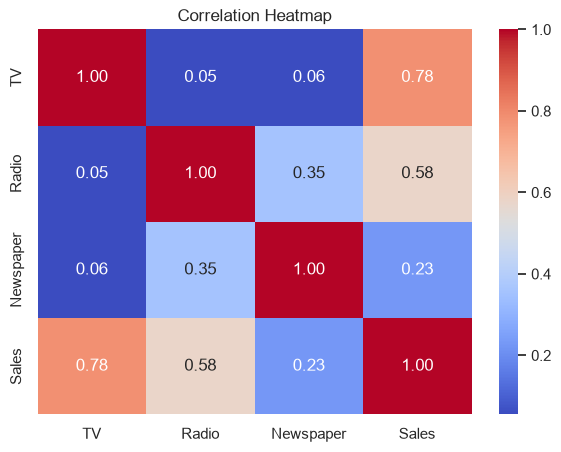

Sales        1.000000
TV           0.782224
Radio        0.576223
Newspaper    0.228299
Name: Sales, dtype: float64


In [6]:
plt.figure(figsize=(7, 5))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

print(df.corr(numeric_only=True)["Sales"].sort_values(ascending=False))

### Train-Test Split

In [7]:
X = df[["TV", "Radio", "Newspaper"]]
y = df["Sales"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)
print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (160, 3)
Testing Data: (40, 3)


### Linear Regression Model

In [8]:
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)
lr_predictions = lr_model.predict(X_test)
print("Linear Regression Model Trained")
print("\nIntercept:", lr_model.intercept_)
print("\nCoefficients:")
for feature, coef in zip(X.columns, lr_model.coef_):
    print(f"{feature}: {coef:.4f}")

Linear Regression Model Trained

Intercept: 2.979067338122629

Coefficients:
TV: 0.0447
Radio: 0.1892
Newspaper: 0.0028


### Random Forest Model

In [9]:
rf_model = RandomForestRegressor(n_estimators=200, random_state=42)
rf_model.fit(X_train, y_train)
rf_predictions = rf_model.predict(X_test)
print("Random Forest Model Trained")

Random Forest Model Trained


### Model Evaluation

In [10]:
def evaluate_model(name, actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    r2 = r2_score(actual, predicted)
    return {"Model": name, "MAE": mae, "RMSE": rmse, "R2 Score": r2}
results = pd.DataFrame([evaluate_model("Linear Regression", y_test, lr_predictions), evaluate_model("Random Forest", y_test, rf_predictions)])
print(results.round(4))

               Model     MAE    RMSE  R2 Score
0  Linear Regression  1.4608  1.7816    0.8994
1      Random Forest  0.6289  0.7577    0.9818


### Best Model

In [11]:
best_row = results.loc[results["RMSE"].idxmin()]
best_model_name = best_row["Model"]
if best_model_name == "Linear Regression":
    best_model = lr_model
    best_predictions = lr_predictions
else:
    best_model = rf_model
    best_predictions = rf_predictions
print("Best Model:", best_model_name)
print("Best Model RMSE:", round(best_row["RMSE"], 4))
print("Best Model R2:", round(best_row["R2 Score"], 4))

Best Model: Random Forest
Best Model RMSE: 0.7577
Best Model R2: 0.9818


### Residual Plot

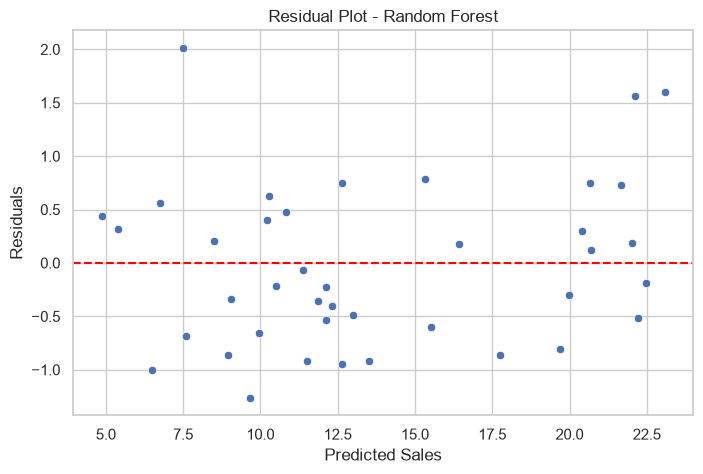

In [12]:
residuals = y_test - best_predictions
plt.figure(figsize=(8, 5))
sns.scatterplot(x=best_predictions, y=residuals)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Predicted Sales")
plt.ylabel("Residuals")
plt.title("Residual Plot - " + best_model_name)
plt.show()

### Feature Importance

TV           0.624729
Radio        0.362129
Newspaper    0.013142
dtype: float64


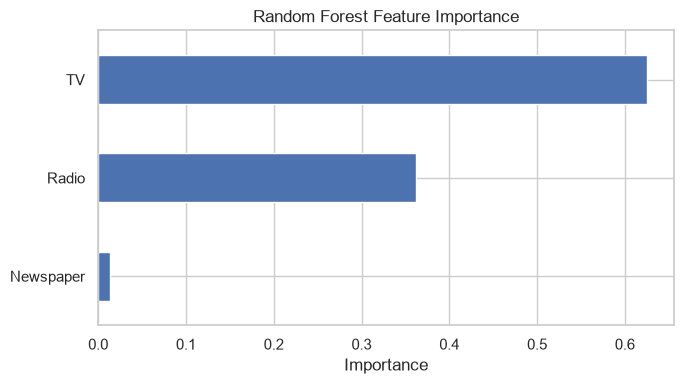

In [13]:
importance = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values(ascending=False)
print(importance)
importance.sort_values().plot(kind="barh", figsize=(7, 4), title="Random Forest Feature Importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

### New Sales Prediction

In [14]:
new_data = pd.DataFrame({"TV": [200], "Radio": [40], "Newspaper": [30]})
prediction = best_model.predict(new_data)
print("Predicted Sales:", round(prediction[0], 2))

Predicted Sales: 20.4


### Save Model

In [15]:
import pickle
with open("sales_prediction_model.pkl", "wb") as file:
    pickle.dump(best_model, file)
print("Model saved successfully!")

Model saved successfully!
